In [71]:
import pandas as pd
import numpy as np

In [72]:
ipl = pd.read_csv('ipl-matches.csv')
diabetes=pd.read_csv('diabetes.csv')
runs = pd.read_csv('batsman_runs_ipl.csv')
movies=pd.read_csv('movies.csv')

In [73]:
# sort_values() practise

In [74]:
# Find which player has won most player of the match
imp_matches= ~ipl['MatchNumber'].str.isdigit()
ipl[imp_matches]['Player_of_Match'].value_counts().sort_values(ascending=False)

Player_of_Match
F du Plessis         3
KA Pollard           3
SK Raina             3
JJ Bumrah            2
SR Watson            2
AB de Villiers       2
MK Pandey            2
M Vijay              2
YK Pathan            2
A Kumble             2
HH Pandya            1
JC Buttler           1
RM Patidar           1
DA Miller            1
VR Iyer              1
SP Narine            1
RD Gaikwad           1
TA Boult             1
MP Stoinis           1
KS Williamson        1
RR Pant              1
SA Yadav             1
Rashid Khan          1
AD Russell           1
KH Pandya            1
KV Sharma            1
NM Coulter-Nile      1
Washington Sundar    1
BCJ Cutting          1
DA Warner            1
MC Henriques         1
RG Sharma            1
A Nehra              1
V Sehwag             1
UT Yadav             1
Harbhajan Singh      1
BJ Hodge             1
MEK Hussey           1
MS Bisla             1
MS Dhoni             1
CH Gayle             1
MM Patel             1
DE Bollinger      

<Axes: ylabel='TossDecision'>

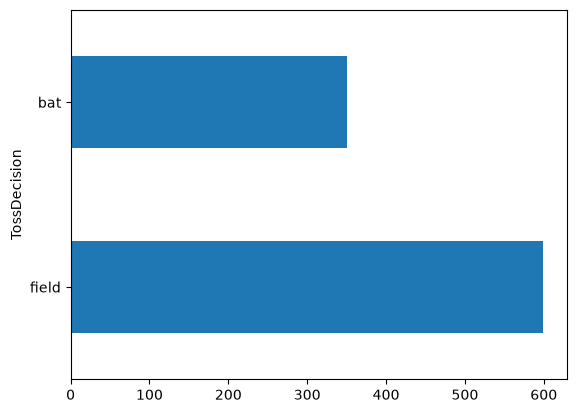

In [75]:
# toss decision plot
ipl['TossDecision'].value_counts().plot(kind='barh')

In [76]:
# how many matches each team has played
(ipl['Team1'].value_counts() + ipl['Team2'].value_counts()).sort_values(ascending=False)

Team1
Mumbai Indians                 231
Royal Challengers Bangalore    226
Kolkata Knight Riders          223
Chennai Super Kings            208
Rajasthan Royals               192
Kings XI Punjab                190
Delhi Daredevils               161
Sunrisers Hyderabad            152
Deccan Chargers                 75
Delhi Capitals                  63
Pune Warriors                   46
Gujarat Lions                   30
Punjab Kings                    28
Gujarat Titans                  16
Rising Pune Supergiant          16
Lucknow Super Giants            15
Kochi Tuskers Kerala            14
Rising Pune Supergiants         14
Name: count, dtype: int64

In [77]:
# rank() --- Only works on series
# ranking according to runs made by batsman
runs['Rank'] = runs['batsman_run'].rank(ascending=False)
sorted=runs.sort_values('Rank')
sorted.head(3)

,batter,batsman_run,Rank
569,V Kohli,6634,1.0
462,S Dhawan,6244,2.0
130,DA Warner,5883,3.0


In [78]:
#set index and reset index 
chngd_index = sorted.set_index('Rank')
chngd_index

,batter,batsman_run
Rank,,
1.0,V Kohli,6634
2.0,S Dhawan,6244
3.0,DA Warner,5883
4.0,RG Sharma,5881
5.0,SK Raina,5536
...,...,...
594.0,V Pratap Singh,0
594.0,Abdur Razzak,0
594.0,U Kaul,0


In [79]:
chngd_index.reset_index().set_index('batter')

,Rank,batsman_run
batter,,
V Kohli,1.0,6634
S Dhawan,2.0,6244
DA Warner,3.0,5883
RG Sharma,4.0,5881
SK Raina,5.0,5536
...,...,...
V Pratap Singh,594.0,0
Abdur Razzak,594.0,0
U Kaul,594.0,0


In [80]:
# renaming coloumn 
runs.rename(columns={'batsman_run':'Runs'})

,batter,Runs,Rank
0,A Ashish Reddy,280,166.5
1,A Badoni,161,226.0
2,A Chandila,4,535.0
3,A Chopra,53,329.0
4,A Choudhary,25,402.5
...,...,...,...
600,Yash Dayal,0,594.0
601,Yashpal Singh,47,343.0
602,Younis Khan,3,547.5
603,Yuvraj Singh,2754,27.0


In [81]:
# Renaming index
chngd_index.rename(index={1:'Best'}).head()

,batter,batsman_run
Rank,,
Best,V Kohli,6634
2.0,S Dhawan,6244
3.0,DA Warner,5883
4.0,RG Sharma,5881
5.0,SK Raina,5536


In [82]:
# isnull and notnull (works in both dataframe and series) 
ipl['Margin'][ipl['Margin'].notnull()]


0        7.0
1        7.0
2       14.0
3        7.0
4        5.0
       ...  
945      5.0
946      5.0
947      9.0
948     33.0
949    140.0
Name: Margin, Length: 932, dtype: float64

In [83]:
ipl['Player_of_Match'].isnull()

0      False
1      False
2      False
3      False
4      False
       ...  
945    False
946    False
947    False
948    False
949    False
Name: Player_of_Match, Length: 950, dtype: bool

In [84]:
# hasnans ( gives has nans or no in one go)
ipl['Player_of_Match'].hasnans

True

# handling na values

In [85]:
# dropna() [works on both df and series]
ipl.dropna().shape # -----> 19 rows left 
# Reduced the data to work on by lot so not very effective
ipl.dropna(how='all').shape 

(950, 20)

In [86]:
# better way
ipl['Player_of_Match'].dropna().shape

(946,)

In [87]:
# fillna() --> fills out missing val with custom value
noNa_data= ipl.fillna('Unknown')
noNa_data['SuperOver'].hasnans
# But its not very logical to apply in whole dataframe at once
# so wee should apply it column by column according to the suitable value

C:\Users\user\AppData\Local\Temp\ipykernel_30068\815754390.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  noNa_data= ipl.fillna('Unknown')


False

In [88]:
# handling duplicate values

marks = pd.DataFrame([
    [50,30,4],
    [88,43,7],
    [88,32,8],
    [71,49,8],
    [50,30,4]
],columns=['iq','marks','package'])
marks.drop_duplicates(keep='last') #by default it keeps first

,iq,marks,package
1,88,43,7
2,88,32,8
3,71,49,8
4,50,30,4


In [89]:
# find the last match played by Shubman Gill in Mumbai
ipl['all_players'] = ipl['Team1Players'] + ipl['Team2Players']
def shubman(players_list):
    return "Shubman Gill" in players_list

In [90]:
ipl['shubman'] = ipl['all_players'].apply(shubman)
ipl[(ipl['City'] == 'Mumbai') & (ipl['shubman'] == True)].drop_duplicates(['City','shubman'],keep='first')


,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players,shubman
7,1304113,Mumbai,2022-05-19,2022,67,Gujarat Titans,Royal Challengers Bangalore,"Wankhede Stadium, Mumbai",Gujarat Titans,bat,...,Wickets,8.0,NaN,V Kohli,"['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...","['V Kohli', 'F du Plessis', 'GJ Maxwell', 'KD ...",KN Ananthapadmanabhan,GR Sadashiv Iyer,"['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",True


In [91]:
# drop() in series and dataframe ( both row and column removal)
temp_data= pd.Series([3,65,4,7,4,6,5,3,3,6,33])
temp_data.drop(index=[2,7])

0      3
1     65
3      7
4      4
5      6
6      5
8      3
9      6
10    33
dtype: int64

In [92]:
ipl.drop(columns='Margin').head(5)

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WinningTeam,WonBy,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players,shubman
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,...,Gujarat Titans,Wickets,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",True
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,...,Rajasthan Royals,Wickets,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",False
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,...,Royal Challengers Bangalore,Runs,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",False
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,...,Gujarat Titans,Wickets,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",True
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,...,Punjab Kings,Wickets,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...",False


In [93]:
ipl.drop(index=[4,3,5]).head(6)

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players,shubman
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,...,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",True
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,...,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",False
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,...,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",False
6,1304114,Mumbai,2022-05-20,2022,68,Chennai Super Kings,Rajasthan Royals,"Brabourne Stadium, Mumbai",Chennai Super Kings,bat,...,Wickets,5.0,NaN,R Ashwin,"['RD Gaikwad', 'DP Conway', 'MM Ali', 'N Jagad...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,NA Patwardhan,"['RD Gaikwad', 'DP Conway', 'MM Ali', 'N Jagad...",False
7,1304113,Mumbai,2022-05-19,2022,67,Gujarat Titans,Royal Challengers Bangalore,"Wankhede Stadium, Mumbai",Gujarat Titans,bat,...,Wickets,8.0,NaN,V Kohli,"['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...","['V Kohli', 'F du Plessis', 'GJ Maxwell', 'KD ...",KN Ananthapadmanabhan,GR Sadashiv Iyer,"['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",True
8,1304112,Navi Mumbai,2022-05-18,2022,66,Lucknow Super Giants,Kolkata Knight Riders,"Dr DY Patil Sports Academy, Mumbai",Lucknow Super Giants,bat,...,Runs,2.0,NaN,Q de Kock,"['Q de Kock', 'KL Rahul', 'E Lewis', 'DJ Hooda...","['VR Iyer', 'A Tomar', 'N Rana', 'SS Iyer', 'S...",R Pandit,YC Barde,"['Q de Kock', 'KL Rahul', 'E Lewis', 'DJ Hooda...",False
